# Actividad 2. Integración del mapa base y límites territoriales

In [1]:
%pip install plotly geopandas pyogrio

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


# Paso 2. Cargar las librerías y los datos
Usaremos el archivo integrado y los límites territoriales de Natural Earth

In [2]:
import pandas as pd
import geopandas as gpd
import plotly.express as px
import json

In [3]:
# Cargar los datos integrados
df = pd.read_csv(
    "../datos/procesados/EMDAT_integrado_WDI.csv",
    low_memory=False
)

# Cargar los límites territoriales
mapa = gpd.read_file(
    "../datos/geograficos/ne_110m_admin_0_countries"
)

print("Eventos:", len(df))
print("Países del mapa:", len(mapa))
print(mapa.columns.tolist())

Eventos: 10907
Países del mapa: 177
['featurecla', 'scalerank', 'LABELRANK', 'SOVEREIGNT', 'SOV_A3', 'ADM0_DIF', 'LEVEL', 'TYPE', 'TLC', 'ADMIN', 'ADM0_A3', 'GEOU_DIF', 'GEOUNIT', 'GU_A3', 'SU_DIF', 'SUBUNIT', 'SU_A3', 'BRK_DIFF', 'NAME', 'NAME_LONG', 'BRK_A3', 'BRK_NAME', 'BRK_GROUP', 'ABBREV', 'POSTAL', 'FORMAL_EN', 'FORMAL_FR', 'NAME_CIAWF', 'NOTE_ADM0', 'NOTE_BRK', 'NAME_SORT', 'NAME_ALT', 'MAPCOLOR7', 'MAPCOLOR8', 'MAPCOLOR9', 'MAPCOLOR13', 'POP_EST', 'POP_RANK', 'POP_YEAR', 'GDP_MD', 'GDP_YEAR', 'ECONOMY', 'INCOME_GRP', 'FIPS_10', 'ISO_A2', 'ISO_A2_EH', 'ISO_A3', 'ISO_A3_EH', 'ISO_N3', 'ISO_N3_EH', 'UN_A3', 'WB_A2', 'WB_A3', 'WOE_ID', 'WOE_ID_EH', 'WOE_NOTE', 'ADM0_ISO', 'ADM0_DIFF', 'ADM0_TLC', 'ADM0_A3_US', 'ADM0_A3_FR', 'ADM0_A3_RU', 'ADM0_A3_ES', 'ADM0_A3_CN', 'ADM0_A3_TW', 'ADM0_A3_IN', 'ADM0_A3_NP', 'ADM0_A3_PK', 'ADM0_A3_DE', 'ADM0_A3_GB', 'ADM0_A3_BR', 'ADM0_A3_IL', 'ADM0_A3_PS', 'ADM0_A3_SA', 'ADM0_A3_EG', 'ADM0_A3_MA', 'ADM0_A3_PT', 'ADM0_A3_AR', 'ADM0_A3_JP', 'ADM0_A3_

# Paso 3. Preparar los países para relacionarlos con EM-DAT
Utilizaremos el código ISO de tres letras para relacionar los eventos con los límites territoriales.

In [4]:
# Revisar las columnas de identificación
print(df[["ISO", "Country"]].head())
print(mapa[["ADMIN", "ADM0_A3"]].head())

# Contar eventos por país
eventos_pais = (
    df.groupby("ISO")
      .size()
      .reset_index(name="Total_eventos")
)

print(eventos_pais.head())

   ISO      Country
0  ECU      Ecuador
1  KEN        Kenya
2  AFG  Afghanistan
3  AFG  Afghanistan
4  AGO       Angola
                         ADMIN ADM0_A3
0                         Fiji     FJI
1  United Republic of Tanzania     TZA
2               Western Sahara     SAH
3                       Canada     CAN
4     United States of America     USA
   ISO  Total_eventos
0  AFG            182
1  AGO             66
2  AIA              1
3  ALB             30
4  ARE              3


# Paso 4. Crear el mapa mundial interactivo

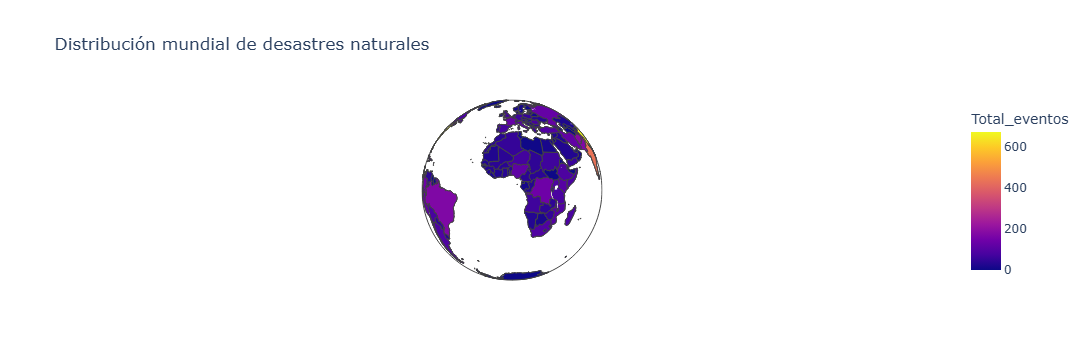

In [5]:
# Unir los límites territoriales con el conteo de eventos
mapa_eventos = mapa.merge(
    eventos_pais,
    left_on="ADM0_A3",
    right_on="ISO",
    how="left"
)

mapa_eventos["Total_eventos"] = (
    mapa_eventos["Total_eventos"].fillna(0)
)

# Crear mapa mundial
fig = px.choropleth(
    mapa_eventos,
    geojson=json.loads(mapa_eventos.to_json()),
    locations="ADM0_A3",
    featureidkey="properties.ADM0_A3",
    color="Total_eventos",
    hover_name="ADMIN",
    hover_data={"Total_eventos": True, "ADM0_A3": False},
    projection="orthographic",
    title="Distribución mundial de desastres naturales"
)

fig.update_geos(
    showcoastlines=True,
    showcountries=True,
    showland=True,
    fitbounds="locations"
)

fig.show()

# Paso 5. Validar la integración

In [6]:
print("Países sin eventos asociados:")
display(
    mapa_eventos.loc[
        mapa_eventos["Total_eventos"] == 0,
        ["ADMIN", "ADM0_A3"]
    ].head(20)
)

print("Países con eventos:", (mapa_eventos["Total_eventos"] > 0).sum())

Países sin eventos asociados:


,ADMIN,ADM0_A3
2,Western Sahara,SAH
20,Falkland Islands,FLK
22,Greenland,GRL
23,French Southern and Antarctic Lands,ATF
79,Palestine,PSX
149,Brunei,BRN
159,Antarctica,ATA
160,Northern Cyprus,CYN
167,Somaliland,SOL
174,Kosovo,KOS


Países con eventos: 166


# Paso 6. Preparar el panel de información por país

In [7]:
# Resumen de desastres por país
panel_paises = (
    df.groupby(["ISO", "Country"], dropna=False)
      .agg(
          Total_eventos=("DisNo.", "count"),
          Total_fallecidos=("Total Deaths", "sum"),
          Total_afectados=("Total Affected", "sum")
      )
      .reset_index()
)

# Ordenar de mayor a menor número de eventos
panel_paises = panel_paises.sort_values(
    "Total_eventos", ascending=False
)

display(panel_paises.head(10))

,ISO,Country,Total_eventos,Total_fallecidos,Total_afectados
34,CHN,China,675,116358.0,1.771309e+09
206,USA,United States of America,660,11649.0,1.047048e+08
85,IND,India,436,93320.0,1.148026e+09
84,IDN,Indonesia,425,191257.0,4.828843e+07
151,PHL,Philippines,406,28309.0,2.586417e+08
212,VNM,Viet Nam,209,5962.0,4.987050e+07
94,JPN,Japan,191,24064.0,5.753346e+06
0,AFG,Afghanistan,182,19157.0,3.745632e+07
148,PAK,Pakistan,174,90221.0,1.029587e+08
26,BRA,Brazil,173,4731.0,5.885381e+07


# Paso 7. Conectar la selección del mapa con la información del país
Para lograr que al hacer clic en un país aparezcan sus indicadores, usaremos Dash, que permite crear aplicaciones interactivas con Plotly.

In [8]:
%pip install dash

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [9]:
import dash
print("Versión de Dash:", dash.__version__)

Versión de Dash: 4.4.1


# Paso 8. Crear la aplicación interactiva

In [10]:
from dash import Dash, dcc, html, Input, Output
import pandas as pd

app = Dash(__name__)

app.layout = html.Div([
    html.H2("Desastres naturales en el mundo"),

    html.P("Haz clic en un país del mapa para consultar sus datos."),

    dcc.Graph(
        id="mapa",
        figure=fig,
        config={"scrollZoom": True}
    ),

    html.H3("Información del país seleccionado"),
    html.Div(
        id="panel",
        children="Selecciona un país en el mapa.",
        style={
            "padding": "15px",
            "border": "1px solid #cccccc",
            "borderRadius": "8px"
        }
    )
])


@app.callback(
    Output("panel", "children"),
    Input("mapa", "clickData")
)
def mostrar_informacion(click_data):

    if not click_data:
        return "Selecciona un país en el mapa."

    codigo = click_data["points"][0].get("location")

    # Buscar el país seleccionado en el mapa
    pais_mapa = mapa_eventos[
        mapa_eventos["ADM0_A3"] == codigo
    ]

    if pais_mapa.empty:
        return "No se encontró información geográfica del país."

    nombre = pais_mapa.iloc[0]["ADMIN"]

    # Buscar los indicadores del país
    datos = panel_paises[
        panel_paises["ISO"].astype(str) == str(codigo)
    ]

    if datos.empty:
      return html.Div([
        html.H4(nombre),
        html.P(
            "No hay registros de desastres asociados "
            "a este territorio en el conjunto de datos."
        ),
        html.P(
            "Esto no confirma que no hayan ocurrido desastres."
        )
    ])

    datos = datos.iloc[0]

    return html.Div([
        html.H4(nombre),
        html.P(f"Total de eventos: {int(datos['Total_eventos']):,}"),
        html.P(f"Total de fallecidos registrados: {datos['Total_fallecidos']:,.0f}"),
        html.P(f"Total de afectados registrados: {datos['Total_afectados']:,.0f}")
    ])


app.run(jupyter_mode="inline", debug=False)

# comprobar paises que no tienen resultados

# Paso 1. Comprobar los códigos que no coinciden
identifica los territorios del mapa sin coincidencia y busca posibles registros por nombre.

In [11]:
# ISO presentes en el mapa
iso_mapa = set(mapa_eventos["ADM0_A3"].astype(str).str.strip())

# ISO presentes en los indicadores
iso_panel = set(panel_paises["ISO"].astype(str).str.strip())

# Territorios del mapa sin registros asociados
sin_coincidencia = mapa_eventos[
    ~mapa_eventos["ADM0_A3"].astype(str).str.strip().isin(iso_panel)
][["ADMIN", "ADM0_A3"]].drop_duplicates()

print(f"Territorios sin coincidencia: {len(sin_coincidencia)}")
display(sin_coincidencia.sort_values("ADMIN"))

Territorios sin coincidencia: 11


,ADMIN,ADM0_A3
159,Antarctica,ATA
149,Brunei,BRN
20,Falkland Islands,FLK
23,French Southern and Antarctic Lands,ATF
22,Greenland,GRL
174,Kosovo,KOS
160,Northern Cyprus,CYN
79,Palestine,PSX
167,Somaliland,SOL
176,South Sudan,SDS


In [12]:
resultados = []

for _, fila in sin_coincidencia.iterrows():

    nombre = str(fila["ADMIN"]).strip()
    iso = fila["ADM0_A3"]

    encontrados = df[
        df["Country"].astype(str).str.contains(
            nombre,
            case=False,
            na=False,
            regex=False
        )
    ]

    if not encontrados.empty:

        paises = (
            encontrados["Country"]
            .drop_duplicates()
            .tolist()
        )

        resultados.append({
            "ISO_mapa": iso,
            "Territorio_mapa": nombre,
            "Coincidencias_EMDAT": ", ".join(paises)
        })

posibles = pd.DataFrame(resultados)

print("POSIBLES COINCIDENCIAS POR NOMBRE")
display(posibles)

POSIBLES COINCIDENCIAS POR NOMBRE


,ISO_mapa,Territorio_mapa,Coincidencias_EMDAT
0,PSX,Palestine,State of Palestine
1,SDS,South Sudan,South Sudan


Y para los casos donde el nombre sea diferente (por ejemplo Czechia vs Czech Republic), usamos coincidencia aproximada:

In [13]:
from difflib import get_close_matches

paises_emdat = (
    df["Country"]
    .dropna()
    .astype(str)
    .unique()
)

revision = []

for _, fila in sin_coincidencia.iterrows():

    nombre = str(fila["ADMIN"]).strip()

    sugerencias = get_close_matches(
        nombre,
        paises_emdat,
        n=3,
        cutoff=0.60
    )

    revision.append({
        "ISO_mapa": fila["ADM0_A3"],
        "Territorio_mapa": nombre,
        "Posibles_EMDAT": ", ".join(sugerencias)
    })

revision = pd.DataFrame(revision)

print("COINCIDENCIAS APROXIMADAS")
display(revision)

COINCIDENCIAS APROXIMADAS


,ISO_mapa,Territorio_mapa,Posibles_EMDAT
0,SAH,Western Sahara,
1,FLK,Falkland Islands,"Cayman Islands, Marshall Islands, Wallis and F..."
2,GRL,Greenland,"Ireland, Grenada, Iceland"
3,ATF,French Southern and Antarctic Lands,
4,PSX,Palestine,State of Palestine
5,BRN,Brunei,Burundi
6,ATA,Antarctica,
7,CYN,Northern Cyprus,
8,SOL,Somaliland,"Somalia, Thailand, Poland"
9,KOS,Kosovo,


In [14]:
revision[
    revision["Posibles_EMDAT"].str.len() > 0
].sort_values("Territorio_mapa")

,ISO_mapa,Territorio_mapa,Posibles_EMDAT
5,BRN,Brunei,Burundi
1,FLK,Falkland Islands,"Cayman Islands, Marshall Islands, Wallis and F..."
2,GRL,Greenland,"Ireland, Grenada, Iceland"
4,PSX,Palestine,State of Palestine
8,SOL,Somaliland,"Somalia, Thailand, Poland"
10,SDS,South Sudan,"South Sudan, Sudan, South Africa"


# crear una tabla de equivalencias

comprobar cada resultado

In [15]:
# VALIDACIÓN Y CORRECCIÓN DE TERRITORIOS

casos = [
    {"ISO_mapa": "BRN", "Territorio_mapa": "Brunei"},
    {"ISO_mapa": "FLK", "Territorio_mapa": "Falkland Islands"},
    {"ISO_mapa": "GRL", "Territorio_mapa": "Greenland"},
    {"ISO_mapa": "PSX", "Territorio_mapa": "Palestine"},
    {"ISO_mapa": "SOL", "Territorio_mapa": "Somaliland"},
    {"ISO_mapa": "SDS", "Territorio_mapa": "South Sudan"}
]

resultado_final = []

for caso in casos:

    iso = caso["ISO_mapa"]
    pais = caso["Territorio_mapa"]

    # BRUNEI
    
    if iso == "BRN":

        encontrados = df[
            df["Country"]
            .astype(str)
            .str.contains(
                "Brunei",
                case=False,
                na=False
            )
        ]

        resultado_final.append({
            "ISO_mapa": iso,
            "Territorio": pais,
            "Coincidencia_real":
                encontrados["Country"].drop_duplicates().tolist(),
            "Accion":
                "Usar registros de Brunei/Brunei Darussalam"
                if not encontrados.empty
                else "Sin coincidencia"
        })

    # FALKLAND ISLANDS

    elif iso == "FLK":

        encontrados = df[
            df["Country"]
            .astype(str)
            .str.contains(
                "Falkland",
                case=False,
                na=False
            )
        ]

        resultado_final.append({
            "ISO_mapa": iso,
            "Territorio": pais,
            "Coincidencia_real":
                encontrados["Country"].drop_duplicates().tolist(),
            "Accion":
                "Usar datos encontrados"
                if not encontrados.empty
                else "Mantener sin datos"
        })

    # GREENLAND

    elif iso == "GRL":

        encontrados = df[
            df["Country"]
            .astype(str)
            .str.contains(
                "Greenland",
                case=False,
                na=False
            )
        ]

        resultado_final.append({
            "ISO_mapa": iso,
            "Territorio": pais,
            "Coincidencia_real":
                encontrados["Country"].drop_duplicates().tolist(),
            "Accion":
                "Usar datos encontrados"
                if not encontrados.empty
                else "Mantener sin datos"
        })

    # PALESTINE

    elif iso == "PSX":

        encontrados = df[
            df["Country"]
            .astype(str)
            .str.contains(
                "State of Palestine",
                case=False,
                na=False
            )
        ]

        resultado_final.append({
            "ISO_mapa": iso,
            "Territorio": pais,
            "Coincidencia_real":
                encontrados["Country"].drop_duplicates().tolist(),
            "Accion":
                "Asignar datos de State of Palestine"
                if not encontrados.empty
                else "Revisión manual"
        })

    # SOMALILAND

    elif iso == "SOL":

        encontrados = df[
            df["Country"]
            .astype(str)
            .str.contains(
                "Somalia",
                case=False,
                na=False
            )
        ]

        resultado_final.append({
            "ISO_mapa": iso,
            "Territorio": pais,
            "Coincidencia_real":
                encontrados["Country"].drop_duplicates().tolist(),
            "Accion":
                "Decidir si hereda datos de Somalia"
                if not encontrados.empty
                else "Mantener sin datos"
        })

    # SOUTH SUDAN
    
    elif iso == "SDS":

        encontrados = df[
            df["Country"]
            .astype(str)
            .str.contains(
                "South Sudan",
                case=False,
                na=False
            )
        ]

        resultado_final.append({
            "ISO_mapa": iso,
            "Territorio": pais,
            "Coincidencia_real":
                encontrados["Country"].drop_duplicates().tolist(),
            "Accion":
                "Asignar datos de South Sudan"
                if not encontrados.empty
                else "Revisión manual"
        })

# TABLA DE VALIDACIÓN

validacion = pd.DataFrame(resultado_final)

print("RESULTADO DE LA REVISIÓN")
display(validacion)

# CORRECCIONES DEFINITIVAS

equivalencias_manual = {
    "PSX": "State of Palestine",
    "SDS": "South Sudan"
}

# Somaliland hereda Somalia (opcional)
usar_somalia_para_somaliland = True

panel_corregido = panel_paises.copy()

for iso_mapa, nombre_emdat in equivalencias_manual.items():

    datos = df[
        df["Country"]
        .astype(str)
        .str.contains(
            nombre_emdat,
            case=False,
            na=False
        )
    ]

    if not datos.empty:

        fila = pd.DataFrame({
            "ISO": [iso_mapa],
            "Total_eventos": [len(datos)],
            "Total_fallecidos": [
                datos["Total Deaths"].fillna(0).sum()
            ],
            "Total_afectados": [
                datos["Total Affected"].fillna(0).sum()
            ]
        })

        panel_corregido = panel_corregido[
            panel_corregido["ISO"] != iso_mapa
        ]

        panel_corregido = pd.concat(
            [panel_corregido, fila],
            ignore_index=True
        )

print("Correcciones aplicadas correctamente")
display(
    panel_corregido[
        panel_corregido["ISO"].isin(
            ["BRN", "FLK", "GRL", "PSX", "SOL", "SDS"]
        )
    ]
)

RESULTADO DE LA REVISIÓN


,ISO_mapa,Territorio,Coincidencia_real,Accion
0,BRN,Brunei,[],Sin coincidencia
1,FLK,Falkland Islands,[],Mantener sin datos
2,GRL,Greenland,[],Mantener sin datos
3,PSX,Palestine,[State of Palestine],Asignar datos de State of Palestine
4,SOL,Somaliland,[Somalia],Decidir si hereda datos de Somalia
5,SDS,South Sudan,[South Sudan],Asignar datos de South Sudan


Correcciones aplicadas correctamente


,ISO,Country,Total_eventos,Total_fallecidos,Total_afectados
220,PSX,NaN,9,35.0,364141.0
221,SDS,NaN,30,2097.0,23046070.0


In [16]:
panel_corregido.loc[
    panel_corregido["ISO"] == "PSX",
    "Country"
] = "State of Palestine"

panel_corregido.loc[
    panel_corregido["ISO"] == "SDS",
    "Country"
] = "South Sudan"

In [17]:
panel_corregido.loc[
    panel_corregido["ISO"] == "SOL",
    "Country"
] = "Somaliland"

Verificar qué territorios siguen sin correspondencia

In [18]:
iso_mapa = set(
    mapa_eventos["ADM0_A3"].astype(str)
)

iso_panel = set(
    panel_corregido["ISO"].astype(str)
)

faltantes = iso_mapa - iso_panel

mapa_eventos[
    mapa_eventos["ADM0_A3"].isin(faltantes)
][["ADM0_A3", "ADMIN"]]

,ADM0_A3,ADMIN
2,SAH,Western Sahara
20,FLK,Falkland Islands
22,GRL,Greenland
23,ATF,French Southern and Antarctic Lands
149,BRN,Brunei
159,ATA,Antarctica
160,CYN,Northern Cyprus
167,SOL,Somaliland
174,KOS,Kosovo


In [19]:
df[
    df["Country"]
    .astype(str)
    .str.contains(
        "Brunei",
        case=False,
        na=False
    )
][["ISO", "Country"]].drop_duplicates()

,ISO,Country


# Paso 9. Actualizar el mapa con panel_corregido

no asignaremos los datos de Somalia a Somalilandia: eso atribuiría eventos de un territorio a otro. Groenlandia, Antártida y Brunei permanecerán sin indicadores mientras no encontremos registros que correspondan realmente a ellos

In [20]:
# ACTUALIZAR MAPA CON LOS DATOS CORREGIDOS

# Preparar una tabla con un solo registro por código ISO
panel_mapa = (
    panel_corregido
    .groupby("ISO", as_index=False)
    .agg(Total_eventos=("Total_eventos", "sum"))
)

# Evitar duplicar columnas al realizar la unión
mapa_eventos = mapa_eventos.drop(
    columns=["ISO", "Total_eventos"],
    errors="ignore"
)

# Unir los indicadores corregidos con los territorios
mapa_eventos = mapa_eventos.merge(
    panel_mapa,
    left_on="ADM0_A3",
    right_on="ISO",
    how="left"
)

# Los territorios sin coincidencia permanecen sin datos
print("Territorios:", len(mapa_eventos))
print("Territorios con indicadores:",
      mapa_eventos["Total_eventos"].notna().sum())

display(
    mapa_eventos.loc[
        mapa_eventos["ADM0_A3"].isin(["PSX", "SDS", "GRL", "BRN", "ATA"]),
        ["ADMIN", "ADM0_A3", "Total_eventos"]
    ]
)

Territorios: 177
Territorios con indicadores: 168


,ADMIN,ADM0_A3,Total_eventos
22,Greenland,GRL,NaN
79,Palestine,PSX,9.0
149,Brunei,BRN,NaN
159,Antarctica,ATA,NaN
176,South Sudan,SDS,30.0


In [21]:
app.run(
    jupyter_mode="inline",
    debug=False
)

# Paso 10. Actualizar el mapa mundial

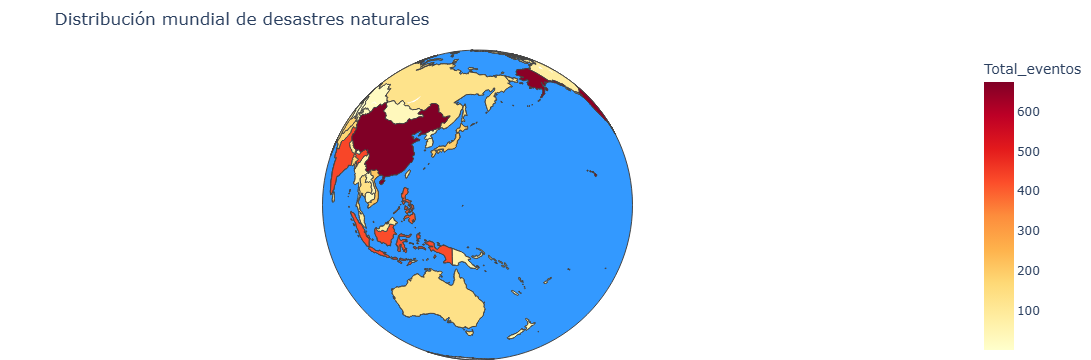

In [22]:
# Crear GeoJSON con los límites territoriales actualizados
geojson_mundo = json.loads(mapa_eventos.to_json())

fig = px.choropleth(
    mapa_eventos,
    geojson=geojson_mundo,
    locations="ADM0_A3",
    featureidkey="properties.ADM0_A3",
    color="Total_eventos",
    hover_name="ADMIN",
    hover_data={
        "Total_eventos": True,
        "ADM0_A3": False
    },
    projection="orthographic",
    color_continuous_scale="YlOrRd",
    title="Distribución mundial de desastres naturales"
)

fig.update_geos(
    showcoastlines=True,
    showcountries=True,
    showland=True,
    showocean=True
)

fig.update_layout(
    margin={"r": 0, "t": 50, "l": 0, "b": 0}
)

fig.show()

# Paso 11. Actualizar el panel interactivo

In [23]:
@app.callback(
    Output("panel", "children"),
    Input("mapa", "clickData")
)
def mostrar_informacion(click_data):

    if not click_data:
        return "Selecciona un país en el mapa."

    codigo = click_data["points"][0].get("location")

    # Buscar el territorio seleccionado
    territorio = mapa_eventos[
        mapa_eventos["ADM0_A3"] == codigo
    ]

    if territorio.empty:
        return "No se encontró el territorio seleccionado."

    nombre = territorio.iloc[0]["ADMIN"]

    # Consultar la tabla corregida
    datos = panel_corregido[
        panel_corregido["ISO"].astype(str).str.strip() == str(codigo)
    ]

    if datos.empty:
        return html.Div([
            html.H4(nombre),
            html.P("No hay indicadores asociados a este código."),
            html.P("La ausencia de datos no confirma que no hayan ocurrido desastres.")
        ])

    datos = datos.iloc[0]

    # Mostrar indicadores
    fallecidos = datos.get("Total_fallecidos", float("nan"))
    afectados = datos.get("Total_afectados", float("nan"))

    return html.Div([
        html.H4(nombre),
        html.P(f"Total de eventos: {int(datos['Total_eventos']):,}"),
        html.P(
            "Total de fallecidos registrados: "
            + (f"{fallecidos:,.0f}" if pd.notna(fallecidos) else "Sin datos")
        ),
        html.P(
            "Total de afectados registrados: "
            + (f"{afectados:,.0f}" if pd.notna(afectados) else "Sin datos")
        )
    ])

# Paso 12. Mejorar el panel de información

In [50]:

from dash import dcc, html

buscador_paises = dcc.Dropdown(
    id="buscador-pais",
    options=[
        {"label": fila["Nombre_es"], "value": fila["Codigo_mapa"]}
        for _, fila in mapa_final.sort_values("Nombre_es").iterrows()
    ],
    placeholder="Busca un país o territorio...",
    searchable=True,
    clearable=True
)

app.layout = html.Div(
    style={
        "fontFamily": "Arial",
        "maxWidth": "1200px",
        "margin": "auto",
        "padding": "20px"
    },
    children=[
        html.H1(
            "Desastres naturales en el mundo",
            style={"textAlign": "center"}
        ),

        html.P(
            "Selecciona un territorio en el globo para consultar "
            "sus indicadores registrados.",
            style={"textAlign": "center"}
        ),

        dcc.Graph(
            id="mapa",
            figure=fig,
            config={"scrollZoom": True}
        ),

        html.H2("Información del territorio seleccionado"),

        html.Div(
            id="panel",
            children="Selecciona un territorio en el mapa.",
            style={
                "padding": "20px",
                "border": "1px solid #cccccc",
                "borderRadius": "10px",
                "backgroundColor": "#f7f7f7"
            }
        )
    ]
)

In [25]:
app.run()

# Paso 13: validar la consistencia entre el mapa y el panel de información.

In [26]:
# ==========================================
# VALIDACIÓN MAPA VS. PANEL
# ==========================================

# Resumir eventos por código ISO en el panel corregido
eventos_panel = (
    panel_corregido
    .groupby("ISO", as_index=False)
    .agg(Eventos_panel=("Total_eventos", "sum"))
)

# Comparar con los valores del mapa
comparacion = mapa_eventos[
    ["ADMIN", "ADM0_A3", "Total_eventos"]
].merge(
    eventos_panel,
    left_on="ADM0_A3",
    right_on="ISO",
    how="left"
)

# Comparar únicamente donde ambos valores existen
comparacion["Coincide"] = (
    comparacion["Total_eventos"].notna()
    & comparacion["Eventos_panel"].notna()
    & (
        comparacion["Total_eventos"]
        == comparacion["Eventos_panel"]
    )
)

# Resumen
comparables = (
    comparacion["Total_eventos"].notna()
    & comparacion["Eventos_panel"].notna()
)

discrepancias = comparacion[
    comparables & ~comparacion["Coincide"]
]

sin_indicadores = comparacion[
    comparacion["Eventos_panel"].isna()
]

print("Territorios comparables:", int(comparables.sum()))
print("Coincidencias:", int(comparacion["Coincide"].sum()))
print("Discrepancias:", len(discrepancias))
print("Territorios sin indicadores asociados:", len(sin_indicadores))

print("\nDiscrepancias encontradas:")
display(discrepancias)

print("\nTerritorios sin indicadores asociados:")
display(sin_indicadores[["ADMIN", "ADM0_A3"]])

Territorios comparables: 168
Coincidencias: 168
Discrepancias: 0
Territorios sin indicadores asociados: 9

Discrepancias encontradas:


,ADMIN,ADM0_A3,Total_eventos,ISO,Eventos_panel,Coincide



Territorios sin indicadores asociados:


,ADMIN,ADM0_A3
2,Western Sahara,SAH
20,Falkland Islands,FLK
22,Greenland,GRL
23,French Southern and Antarctic Lands,ATF
149,Brunei,BRN
159,Antarctica,ATA
160,Northern Cyprus,CYN
167,Somaliland,SOL
174,Kosovo,KOS


# Paso 14. Verificar los nueve territorios en EM-DAT
La documentación de EM-DAT explica que sus códigos geográficos pueden incluir extensiones históricas y que los nombres de países siguen el estándar UN M49. Por eso, no basta con comparar los códigos de ambas fuentes.

In [27]:
# INVESTIGAR TERRITORIOS SIN INDICADORES

busquedas = {
    "SAH - Western Sahara": "Western Sahara|Sahrawi|Morocco|Mauritania",
    "FLK - Falkland Islands": "Falkland|Malvinas",
    "GRL - Greenland": "Greenland|Denmark",
    "ATF - French Southern and Antarctic Lands": "French Southern|Antarctic",
    "BRN - Brunei": "Brunei",
    "ATA - Antarctica": "Antarctica",
    "CYN - Northern Cyprus": "Northern Cyprus|Cyprus",
    "SOL - Somaliland": "Somaliland|Somalia",
    "KOS - Kosovo": "Kosovo|Serbia"
}

paises_emdat = df[["ISO", "Country"]].drop_duplicates().copy()

for territorio, patron in busquedas.items():
    encontrados = paises_emdat[
        paises_emdat["Country"].astype(str).str.contains(
            patron, case=False, na=False, regex=True
        )
    ]

    print(f"\n{territorio}")
    if encontrados.empty:
        print("Sin coincidencias por nombre.")
    else:
        display(encontrados.sort_values("Country"))


SAH - Western Sahara


,ISO,Country
629,MRT,Mauritania
22,MAR,Morocco



FLK - Falkland Islands
Sin coincidencias por nombre.

GRL - Greenland


,ISO,Country
191,DNK,Denmark



ATF - French Southern and Antarctic Lands
Sin coincidencias por nombre.

BRN - Brunei
Sin coincidencias por nombre.

ATA - Antarctica
Sin coincidencias por nombre.

CYN - Northern Cyprus


,ISO,Country
182,CYP,Cyprus



SOL - Somaliland


,ISO,Country
5,SOM,Somalia



KOS - Kosovo


,ISO,Country
219,SRB,Serbia
2493,SCG,Serbia Montenegro


# Paso 15. Clasificar los territorios sin indicadores
La solución correcta no es asignarles datos de países vecinos, sino documentar qué sabemos de cada territorio. EM-DAT utiliza códigos ISO y también conserva ciertos códigos históricos propios, por lo que las coincidencias deben verificarse antes de integrarlas.

In [28]:
# CLASIFICAR TERRITORIOS SIN INDICADORES

clasificacion = {
    "SAH": (
        "Revisión territorial",
        "No asignar eventos de Marruecos o Mauritania sin "
        "confirmar que corresponden al Sáhara Occidental."
    ),
    "FLK": (
        "Sin registros directos identificados",
        "No se encontraron coincidencias por nombre en EM-DAT."
    ),
    "GRL": (
        "Cobertura territorial no confirmada",
        "Se encontraron registros de Dinamarca, pero no "
        "se confirmó información independiente de Groenlandia."
    ),
    "ATF": (
        "Sin registros independientes identificados",
        "No se encontraron coincidencias por nombre en EM-DAT."
    ),
    "BRN": (
        "Sin registros directos identificados",
        "No se encontraron coincidencias por nombre en EM-DAT."
    ),
    "ATA": (
        "Sin registros directos identificados",
        "No se encontraron coincidencias por nombre en EM-DAT."
    ),
    "CYN": (
        "Cobertura territorial no confirmada",
        "Se encontraron registros de Chipre, pero no se confirmó "
        "qué eventos corresponden a Chipre del Norte."
    ),
    "SOL": (
        "Sin registros independientes confirmados",
        "No asignar automáticamente los eventos de Somalia."
    ),
    "KOS": (
        "Cobertura territorial no confirmada",
        "No asignar automáticamente los eventos de Serbia "
        "o Serbia-Montenegro."
    )
}

mapa_eventos["Estado_datos"] = "Con indicadores asociados"
mapa_eventos["Observacion_datos"] = "Datos asociados mediante el código geográfico."

for codigo, (estado, observacion) in clasificacion.items():
    filtro = mapa_eventos["ADM0_A3"] == codigo
    mapa_eventos.loc[filtro, "Estado_datos"] = estado
    mapa_eventos.loc[filtro, "Observacion_datos"] = observacion

# Mostrar el resultado
display(
    mapa_eventos.loc[
        mapa_eventos["ADM0_A3"].isin(clasificacion),
        ["ADMIN", "ADM0_A3", "Total_eventos",
         "Estado_datos", "Observacion_datos"]
    ]
)

,ADMIN,ADM0_A3,Total_eventos,Estado_datos,Observacion_datos
2,Western Sahara,SAH,NaN,Revisión territorial,No asignar eventos de Marruecos o Mauritania s...
20,Falkland Islands,FLK,NaN,Sin registros directos identificados,No se encontraron coincidencias por nombre en ...
22,Greenland,GRL,NaN,Cobertura territorial no confirmada,"Se encontraron registros de Dinamarca, pero no..."
23,French Southern and Antarctic Lands,ATF,NaN,Sin registros independientes identificados,No se encontraron coincidencias por nombre en ...
149,Brunei,BRN,NaN,Sin registros directos identificados,No se encontraron coincidencias por nombre en ...
159,Antarctica,ATA,NaN,Sin registros directos identificados,No se encontraron coincidencias por nombre en ...
160,Northern Cyprus,CYN,NaN,Cobertura territorial no confirmada,"Se encontraron registros de Chipre, pero no se..."
167,Somaliland,SOL,NaN,Sin registros independientes confirmados,No asignar automáticamente los eventos de Soma...
174,Kosovo,KOS,NaN,Cobertura territorial no confirmada,No asignar automáticamente los eventos de Serb...


nota: EM-DAT registra desastres que cumplen criterios de inclusión específicos, como al menos 10 fallecidos, 100 personas afectadas, 
una declaración de emergencia o una solicitud de asistencia internacional. Por eso, que un territorio no tenga filas en tu archivo 
no significa que nunca haya sufrido desastres.

# Territorio y  su decisión recomendada
- Western Sahara (SAH) Conservar el nombre. No asignar automáticamente eventos de Marruecos o Mauritania. La ONU lo incluye entre los territorios no autónomos. 

- Falkland Islands (FLK)	Conservar el nombre. No hay coincidencia directa en tu archivo; no asignar datos de Argentina ni del Reino Unido sin evidencia geográfica específica.

- Greenland (GRL)	Conservar el nombre. La ONU reconoce a Groenlandia como una unidad geográfica con código GRL; no usar los eventos de Dinamarca como sustituto. 

- French Southern and Antarctic Lands (ATF)	Conservar el territorio representado por Natural Earth. No asignar automáticamente los eventos de Francia. EM-DAT utiliza el nombre French Southern Territories para ATF. 

- Brunei (BRN)	Conservar el nombre y el código. BRN es un código válido para Brunéi; como no encontraste registros, la explicación más compatible con la evidencia actual es que no tiene eventos incluidos en el archivo analizado, no que deba heredar datos de otro país. 

- Antarctica (ATA)	Conservarla en el globo, pero tratarla como un territorio sin indicadores directos en el archivo. No asignar eventos de ningún otro país.

- Northern Cyprus (CYN)	Conservar la geometría si quieres mostrar el territorio por separado, pero no asignarle todos los eventos de Chipre. El norte de la isla no es reconocido como Estado independiente por la mayoría de la comunidad internacional. 

- Somaliland (SOL)	Conservar el nombre de la entidad geográfica, pero no transferirle los eventos de Somalia. La ONU continúa destacando la integridad territorial de Somalia, aunque la situación diplomática de Somalilandia tuvo novedades recientes. 

- Kosovo (KOS)	Conservar el territorio, pero no asignarle los eventos de Serbia o de Serbia-Montenegro sin confirmar dónde ocurrió cada desastre. Los registros históricos de Serbia-Montenegro tampoco equivalen automáticamente a registros de Kosovo. 

La diferencia esencial es que Brunéi, Groenlandia y las Islas Malvinas tienen códigos geográficos reconocidos, mientras que entidades como Somalilandia y Chipre del Norte requieren un tratamiento especial por su situación territorial y por cómo se registran los datos. La existencia de un polígono en Natural Earth no garantiza que EM-DAT tenga una unidad estadística equivalente.

In [29]:
# Códigos que debemos comprobar en EM-DAT
codigos_revision = [
    "ESH", "SAH", "FLK", "GRL", "ATF",
    "BRN", "ATA", "CYP", "CYN",
    "SOM", "SOL", "SRB", "SCG", "KOS", "XKX"
]

revision_iso = (
    df.loc[
        df["ISO"].astype(str).str.strip().isin(codigos_revision),
        ["ISO", "Country"]
    ]
    .drop_duplicates()
    .sort_values(["ISO", "Country"])
)

display(revision_iso)

,ISO,Country
182,CYP,Cyprus
2493,SCG,Serbia Montenegro
5,SOM,Somalia
219,SRB,Serbia


guardar la clasificación definitiva

In [30]:
# Clasificación de disponibilidad de indicadores
mapa_eventos["Disponibilidad"] = "Con indicadores asociados"

sin_indicadores = [
    "SAH", "FLK", "GRL", "ATF", "BRN",
    "ATA", "CYN", "SOL", "KOS"
]

mapa_eventos.loc[
    mapa_eventos["ADM0_A3"].isin(sin_indicadores),
    "Disponibilidad"
] = "Sin indicadores directos identificados"

display(
    mapa_eventos.loc[
        mapa_eventos["ADM0_A3"].isin(sin_indicadores),
        ["ADMIN", "ADM0_A3", "Disponibilidad"]
    ]
)

,ADMIN,ADM0_A3,Disponibilidad
2,Western Sahara,SAH,Sin indicadores directos identificados
20,Falkland Islands,FLK,Sin indicadores directos identificados
22,Greenland,GRL,Sin indicadores directos identificados
23,French Southern and Antarctic Lands,ATF,Sin indicadores directos identificados
149,Brunei,BRN,Sin indicadores directos identificados
159,Antarctica,ATA,Sin indicadores directos identificados
160,Northern Cyprus,CYN,Sin indicadores directos identificados
167,Somaliland,SOL,Sin indicadores directos identificados
174,Kosovo,KOS,Sin indicadores directos identificados


# Paso 1: Crear una copia de seguridad y la tabla de tratamiento

In [31]:

# 1. Crear copias de seguridad
mapa_eventos_original = mapa_eventos.copy(deep=True)
panel_corregido_original = panel_corregido.copy(deep=True)

# 2. Documentar el tratamiento cartográfico
tratamiento_territorial = pd.DataFrame([
    {
        "Codigo": "CYN",
        "Territorio": "Chipre del Norte",
        "Tratamiento": "Integrar geometría con CYP",
        "Motivo": "EM-DAT contiene datos nacionales de Chipre, sin desglose confirmado para el norte."
    },
    {
        "Codigo": "SOL",
        "Territorio": "Somalilandia",
        "Tratamiento": "Integrar geometría con SOM",
        "Motivo": "No se confirmaron indicadores independientes en EM-DAT."
    },
    {
        "Codigo": "KOS",
        "Territorio": "Kosovo",
        "Tratamiento": "Conservar sin indicadores directos",
        "Motivo": "No asignar automáticamente los totales de Serbia."
    },
    {
        "Codigo": "SAH",
        "Territorio": "Sáhara Occidental",
        "Tratamiento": "Conservar sin indicadores directos",
        "Motivo": "No asignar automáticamente los totales de Marruecos o Mauritania."
    },
    {
        "Codigo": "FLK",
        "Territorio": "Islas Malvinas",
        "Tratamiento": "Conservar sin indicadores directos",
        "Motivo": "No se identificaron registros directos por nombre."
    },
    {
        "Codigo": "GRL",
        "Territorio": "Groenlandia",
        "Tratamiento": "Conservar sin indicadores directos",
        "Motivo": "No se confirmó un desglose independiente de Dinamarca."
    },
    {
        "Codigo": "ATF",
        "Territorio": "Tierras Australes Francesas",
        "Tratamiento": "Conservar sin indicadores directos",
        "Motivo": "No se identificaron registros independientes."
    },
    {
        "Codigo": "BRN",
        "Territorio": "Brunéi",
        "Tratamiento": "Revisar código geográfico",
        "Motivo": "No se identificaron coincidencias directas; verificar la equivalencia de códigos."
    },
    {
        "Codigo": "ATA",
        "Territorio": "Antártida",
        "Tratamiento": "Conservar sin indicadores directos",
        "Motivo": "No se identificaron registros directos."
    }
])

# 3. Mostrar la tabla para revisarla
display(tratamiento_territorial)


,Codigo,Territorio,Tratamiento,Motivo
0,CYN,Chipre del Norte,Integrar geometría con CYP,"EM-DAT contiene datos nacionales de Chipre, si..."
1,SOL,Somalilandia,Integrar geometría con SOM,No se confirmaron indicadores independientes e...
2,KOS,Kosovo,Conservar sin indicadores directos,No asignar automáticamente los totales de Serbia.
3,SAH,Sáhara Occidental,Conservar sin indicadores directos,No asignar automáticamente los totales de Marr...
4,FLK,Islas Malvinas,Conservar sin indicadores directos,No se identificaron registros directos por nom...
5,GRL,Groenlandia,Conservar sin indicadores directos,No se confirmó un desglose independiente de Di...
6,ATF,Tierras Australes Francesas,Conservar sin indicadores directos,No se identificaron registros independientes.
7,BRN,Brunéi,Revisar código geográfico,No se identificaron coincidencias directas; ve...
8,ATA,Antártida,Conservar sin indicadores directos,No se identificaron registros directos.


# Paso 2. Revisar las geometrías antes de modificarlas
Primero comprobaremos que los códigos existen, que no están duplicados y que las geometrías son válidas. Esto es importante porque dissolve() combina geometrías, pero también agrega los atributos según la función indicada; no queremos sumar indicadores por accidente.

In [32]:

# Códigos territoriales que revisaremos
codigos_revision = [
    "CYN", "CYP", "SOL", "SOM", "KOS",
    "SRB", "SCG", "SAH", "MAR", "MRT",
    "FLK", "GRL", "ATF", "BRN", "ATA"
]

# 1. Comprobar el sistema de coordenadas
print("Sistema de coordenadas:", mapa_eventos.crs)

# 2. Revisar si hay códigos duplicados
print("\nCódigos geográficos duplicados:")
print(
    mapa_eventos.loc[
        mapa_eventos["ADM0_A3"].duplicated(keep=False),
        ["ADM0_A3", "ADMIN"]
    ].sort_values("ADM0_A3")
)

# 3. Consultar los territorios de interés
revision = mapa_eventos.loc[
    mapa_eventos["ADM0_A3"].isin(codigos_revision),
    ["ADM0_A3", "ADMIN", "Total_eventos",
     "Disponibilidad", "geometry"]
].copy()

revision["Geometria_valida"] = revision.geometry.is_valid
revision["Geometria_vacia"] = revision.geometry.is_empty

display(
    revision.drop(columns="geometry").sort_values("ADM0_A3")
)

print("\nCantidad de territorios encontrados:", len(revision))
print("Geometrías inválidas:", (~revision["Geometria_valida"]).sum())
print("Geometrías vacías:", revision["Geometria_vacia"].sum())


Sistema de coordenadas: EPSG:4326

Códigos geográficos duplicados:
Empty DataFrame
Columns: [ADM0_A3, ADMIN]
Index: []


,ADM0_A3,ADMIN,Total_eventos,Disponibilidad,Geometria_valida,Geometria_vacia
159,ATA,Antarctica,NaN,Sin indicadores directos identificados,True,False
23,ATF,French Southern and Antarctic Lands,NaN,Sin indicadores directos identificados,True,False
149,BRN,Brunei,NaN,Sin indicadores directos identificados,True,False
160,CYN,Northern Cyprus,NaN,Sin indicadores directos identificados,True,False
161,CYP,Cyprus,13.0,Con indicadores asociados,True,False
20,FLK,Falkland Islands,NaN,Sin indicadores directos identificados,True,False
22,GRL,Greenland,NaN,Sin indicadores directos identificados,True,False
174,KOS,Kosovo,NaN,Sin indicadores directos identificados,True,False
162,MAR,Morocco,37.0,Con indicadores asociados,True,False
53,MRT,Mauritania,25.0,Con indicadores asociados,True,False



Cantidad de territorios encontrados: 14
Geometrías inválidas: 0
Geometrías vacías: 0


# Paso 3. Preparar la integración de Chipre del Norte y Somalilandia
vamos a identificar los países que comparten frontera con cada territorio. Esto nos permitirá verificar que las geometrías que pretendemos combinar realmente corresponden a las unidades cartográficas esperadas.

In [33]:

# Copiar las geometrías para preparar la revisión
mapa_revision = mapa_eventos_original.copy()

# Obtener las geometrías de los territorios que queremos revisar
codigos_objetivo = ["CYN", "CYP", "SOL", "SOM"]

for codigo in codigos_objetivo:
    territorio = mapa_revision[
        mapa_revision["ADM0_A3"] == codigo
    ]

    if territorio.empty:
        print(f"\nNo se encontró el código {codigo}.")
        continue

    geometria = territorio.geometry.iloc[0]

    # Buscar territorios cuyas geometrías intersectan la seleccionada
    vecinos = mapa_revision[
        (mapa_revision["ADM0_A3"] != codigo)
        & mapa_revision.geometry.intersects(geometria)
    ][["ADM0_A3", "ADMIN"]]

    print(f"\nTerritorio: {territorio['ADMIN'].iloc[0]} ({codigo})")
    print("Territorios que intersectan su geometría:")
    display(vecinos.reset_index(drop=True))



Territorio: Northern Cyprus (CYN)
Territorios que intersectan su geometría:


,ADM0_A3,ADMIN
0,CYP,Cyprus



Territorio: Cyprus (CYP)
Territorios que intersectan su geometría:


,ADM0_A3,ADMIN
0,CYN,Northern Cyprus



Territorio: Somaliland (SOL)
Territorios que intersectan su geometría:


,ADM0_A3,ADMIN
0,SOM,Somalia
1,ETH,Ethiopia
2,DJI,Djibouti



Territorio: Somalia (SOM)
Territorios que intersectan su geometría:


,ADM0_A3,ADMIN
0,KEN,Kenya
1,ETH,Ethiopia
2,SOL,Somaliland


# Paso 4. Crear el mapa con las geometrías integradas
Vamos a unir CYN con CYP y SOL con SOM únicamente en una copia de la capa geográfica. Los indicadores nacionales se conservarán sin sumarlos ni duplicarlos.

In [34]:

# Trabajar sobre una copia del mapa original
mapa_final = mapa_eventos_original.copy()

# Integrar únicamente las geometrías de estos territorios
fusiones = {
    "CYN": "CYP",
    "SOL": "SOM"
}

mapa_final["Codigo_mapa"] = (
    mapa_final["ADM0_A3"].replace(fusiones)
)

# Combinar geometrías sin sumar indicadores
mapa_final = mapa_final.dissolve(
    by="Codigo_mapa",
    aggfunc={
        "ADMIN": "first",
        "Total_eventos": "first",
        "Disponibilidad": "first",
        "Estado_datos": "first",
        "Observacion_datos": "first"
    }
).reset_index()

# Verificar el resultado
print("Territorios originales:", len(mapa_eventos_original))
print("Unidades cartográficas finales:", len(mapa_final))
print(
    "Códigos duplicados:",
    mapa_final["Codigo_mapa"].duplicated().sum()
)

display(
    mapa_final.loc[
        mapa_final["Codigo_mapa"].isin(["CYP", "SOM"]),
        ["Codigo_mapa", "ADMIN", "Total_eventos"]
    ]
)


Territorios originales: 177
Unidades cartográficas finales: 175
Códigos duplicados: 0


,Codigo_mapa,ADMIN,Total_eventos
38,CYP,Northern Cyprus,13.0
144,SOM,Somalia,82.0


El resultado tiene 175 unidades cartográficas, sin códigos duplicados. Pero CYP aparece con el nombre Northern Cyprus y conserva 13 eventos, lo que indica que dissolve() tomó primero los atributos de CYN, no los de Chipre. La geometría se combinó, hay que corregir el nombre y asegurar que los indicadores correspondan a Chipre.

# Paso 5. Corregir las unidades fusionadas

In [35]:

# Corregir los nombres de las unidades cartográficas fusionadas
mapa_final.loc[
    mapa_final["Codigo_mapa"] == "CYP", "ADMIN"
] = "Cyprus"

mapa_final.loc[
    mapa_final["Codigo_mapa"] == "SOM", "ADMIN"
] = "Somalia"

# Recuperar los indicadores nacionales desde panel_corregido
for codigo in ["CYP", "SOM"]:
    datos = panel_corregido.loc[
        panel_corregido["ISO"] == codigo
    ]

    if not datos.empty:
        print(f"\nIndicadores originales para {codigo}:")
        display(
            datos[
                ["ISO", "Country", "Total_eventos",
                 "Total_fallecidos", "Total_afectados"]
            ]
        )

# Comprobar las unidades cartográficas finales
display(
    mapa_final.loc[
        mapa_final["Codigo_mapa"].isin(["CYP", "SOM"]),
        ["Codigo_mapa", "ADMIN", "Total_eventos"]
    ]
)



Indicadores originales para CYP:


,ISO,Country,Total_eventos,Total_fallecidos,Total_afectados
137,CYP,Cyprus,13,534.0,1658.0



Indicadores originales para SOM:


,ISO,Country,Total_eventos,Total_fallecidos,Total_afectados
37,SOM,Somalia,82,24106.0,43327356.0


,Codigo_mapa,ADMIN,Total_eventos
38,CYP,Cyprus,13.0
144,SOM,Somalia,82.0


# Paso 6. Actualizar el mapa 3D

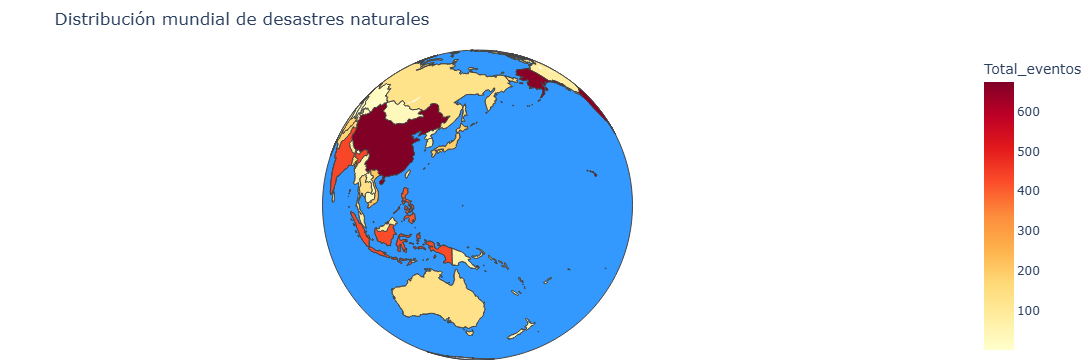

In [37]:
# Preparar GeoJSON con las geometrías finales
geojson_mundo = json.loads(mapa_final.to_json())

fig = px.choropleth(
    mapa_final,
    geojson=geojson_mundo,
    locations="Codigo_mapa",
    featureidkey="properties.Codigo_mapa",
    color="Total_eventos",
    hover_name="ADMIN",
    hover_data={
        "Total_eventos": True,
        "Codigo_mapa": True
    },
    projection="orthographic",
    color_continuous_scale="YlOrRd",
    title="Distribución mundial de desastres naturales"
)

fig.update_geos(
    showcoastlines=True,
    showcountries=True,
    showland=True,
    showocean=True
)

fig.update_layout(
    margin={"r": 0, "t": 50, "l": 0, "b": 0}
)

fig.show()


# Paso 7. Conectar el mapa con el panel de información

In [39]:

from dash import Input, Output, html

@app.callback(
    Output("panel", "children"),
    Input("mapa", "clickData")
)
def mostrar_informacion(click_data):

    if not click_data:
        return html.Div([
            html.H3("Información del país"),
            html.P("Selecciona un país en el mapa.")
        ])

    codigo = click_data["points"][0].get("location")

    # Consultar el país seleccionado
    geometria = mapa_final.loc[
        mapa_final["Codigo_mapa"] == codigo
    ]

    datos = panel_corregido.loc[
        panel_corregido["ISO"] == codigo
    ]

    if geometria.empty:
        return html.P("No se encontró el territorio seleccionado.")

    nombre = geometria["ADMIN"].iloc[0]

    if datos.empty:
        return html.Div([
            html.H3(nombre),
            html.P("Sin indicadores directos identificados en EM-DAT.")
        ])

    datos = datos.iloc[0]

    return html.Div([
        html.H3(nombre),
        html.P(f"Total de eventos: {datos['Total_eventos']:,.0f}"),
        html.P(f"Total de fallecidos: {datos['Total_fallecidos']:,.0f}"),
        html.P(f"Total de afectados: {datos['Total_afectados']:,.0f}")
    ])


In [40]:
app.run()

# Añadir detalles extra
Traduccion de los nombres y buscador de paises

In [52]:
%pip install Babel pycountry dash plotly geopandas

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [54]:

import json
import pandas as pd
import pycountry
import plotly.express as px

from babel import Locale
from dash import Dash, dcc, html, Input, Output, ctx, no_update


# =========================================================
# 1. CONFIGURACIÓN VISUAL
# =========================================================

COLORES = {
    "fondo": "#0B1120",
    "superficie": "#111B2E",
    "superficie2": "#17243A",
    "borde": "#263650",
    "texto": "#F1F5F9",
    "secundario": "#94A3B8",
    "azul": "#60A5FA",
    "turquesa": "#2DD4BF",
    "naranja": "#F59E0B",
    "rojo": "#FB7185"
}

nombres_es = Locale("es").territories

excepciones = {
    "CYP": "Chipre",
    "SOM": "Somalia",
    "KOS": "Kosovo",
    "SAH": "Sáhara Occidental",
    "CYN": "Chipre del Norte",
    "SOL": "Somalilandia",
    "FLK": "Islas Malvinas",
    "GRL": "Groenlandia",
    "ATF": "Tierras Australes y Antárticas Francesas",
    "BRN": "Brunéi",
    "ATA": "Antártida",
    "SCG": "Serbia y Montenegro (histórico)",
    "PSX": "Estado de Palestina",
    "SDS": "Sudán del Sur"
}

nombres_personalizados = {
    "United States of America": "Estados Unidos",
    "Russia": "Rusia",
    "South Korea": "Corea del Sur",
    "North Korea": "Corea del Norte",
    "Ivory Coast": "Costa de Marfil",
    "Dem. Rep. Congo": "República Democrática del Congo",
    "Congo": "República del Congo",
    "Czechia": "Chequia",
    "Taiwan": "Taiwán",
    "Vatican": "Ciudad del Vaticano",
    "Türkiye": "Turquía"
}


# =========================================================
# 2. PREPARAR LOS NOMBRES EN ESPAÑOL
# =========================================================

mapa_app = mapa_final.copy()

def traducir_pais(fila):
    codigo = fila["Codigo_mapa"]

    if codigo in excepciones:
        return excepciones[codigo]

    pais = pycountry.countries.get(alpha_3=codigo)

    if pais:
        return nombres_es.get(pais.alpha_2, fila["ADMIN"])

    return fila["ADMIN"]


mapa_app["Nombre_es"] = mapa_app.apply(
    traducir_pais, axis=1
)

mapa_app["Nombre_es"] = mapa_app.apply(
    lambda fila: nombres_personalizados.get(
        fila["ADMIN"], fila["Nombre_es"]
    ),
    axis=1
)


# =========================================================
# 3. PREPARAR INDICADORES GENERALES
# =========================================================

total_territorios = len(mapa_app)

territorios_con_datos = int(
    mapa_app["Total_eventos"].notna().sum()
)

territorios_sin_datos = (
    total_territorios - territorios_con_datos
)

total_eventos = int(
    mapa_app["Total_eventos"].fillna(0).sum()
)


# =========================================================
# 4. CREAR EL MAPA MUNDIAL 3D
# =========================================================

geojson_mundo = json.loads(mapa_app.to_json())

fig = px.choropleth(
    mapa_app,
    geojson=geojson_mundo,
    locations="Codigo_mapa",
    featureidkey="properties.Codigo_mapa",
    color="Total_eventos",
    hover_name="Nombre_es",
    hover_data={
        "Codigo_mapa": True,
        "Total_eventos": True,
        "Nombre_es": False
    },
    projection="orthographic",
    color_continuous_scale=[
        [0.0, "#172554"],
        [0.25, "#2563EB"],
        [0.50, "#FBBF24"],
        [0.75, "#F97316"],
        [1.0, "#DC2626"]
    ],
    labels={
        "Total_eventos": "Eventos registrados",
        "Codigo_mapa": "Código territorial"
    }
)

fig.update_geos(
    bgcolor=COLORES["superficie"],
    showcoastlines=True,
    coastlinecolor="#64748B",
    showcountries=True,
    countrycolor="#64748B",
    showland=True,
    landcolor="#243248",
    showocean=True,
    oceancolor=COLORES["superficie"],
    showframe=False,
    projection_rotation={"lon": 0, "lat": 15}
)

fig.update_traces(
    marker_line_width=0.45,
    marker_line_color="#64748B",
    hovertemplate=(
        "<b>%{hovertext}</b><br>"
        "Eventos: %{z:,.0f}<br>"
        "Código: %{location}"
        "<extra></extra>"
    )
)

fig.update_layout(
    paper_bgcolor=COLORES["superficie"],
    plot_bgcolor=COLORES["superficie"],
    font={
        "family": "Arial, sans-serif",
        "color": COLORES["texto"],
        "size": 12
    },
    margin={"l": 0, "r": 0, "t": 15, "b": 0},
    height=570,
    clickmode="event+select",
    coloraxis_colorbar={
        "title": {
            "text": "Número de eventos",
            "font": {"color": COLORES["texto"]}
        },
        "tickfont": {"color": COLORES["secundario"]},
        "thickness": 12,
        "len": 0.65,
        "outlinewidth": 0
    }
)


# =========================================================
# 5. FUNCIONES PARA EL DISEÑO
# =========================================================

def tarjeta_estadistica(titulo, valor, descripcion, color, icono):
    return html.Div(
        style={
            "background": COLORES["superficie"],
            "border": f"1px solid {COLORES['borde']}",
            "borderRadius": "14px",
            "padding": "20px",
            "flex": "1",
            "minWidth": "190px",
            "boxShadow": "0 6px 20px rgba(0,0,0,0.12)"
        },
        children=[
            html.Div(
                style={
                    "display": "flex",
                    "justifyContent": "space-between",
                    "alignItems": "center"
                },
                children=[
                    html.Span(
                        titulo,
                        style={
                            "color": COLORES["secundario"],
                            "fontSize": "13px"
                        }
                    ),
                    html.Span(
                        icono,
                        style={
                            "fontSize": "20px",
                            "color": color
                        }
                    )
                ]
            ),
            html.Div(
                f"{valor:,}",
                style={
                    "fontSize": "30px",
                    "fontWeight": "700",
                    "color": COLORES["texto"],
                    "marginTop": "12px"
                }
            ),
            html.Div(
                descripcion,
                style={
                    "fontSize": "12px",
                    "color": COLORES["secundario"],
                    "marginTop": "5px"
                }
            )
        ]
    )


def encabezado_seccion(titulo, subtitulo=None):
    elementos = [
        html.H3(
            titulo,
            style={
                "fontSize": "17px",
                "margin": "0",
                "color": COLORES["texto"]
            }
        )
    ]

    if subtitulo:
        elementos.append(
            html.P(
                subtitulo,
                style={
                    "fontSize": "12px",
                    "color": COLORES["secundario"],
                    "margin": "7px 0 0 0"
                }
            )
        )

    return html.Div(elementos)


def tarjeta_metrica(titulo, valor, color):
    return html.Div(
        style={
            "background": COLORES["superficie2"],
            "padding": "15px",
            "borderRadius": "10px",
            "borderLeft": f"3px solid {color}",
            "marginBottom": "12px"
        },
        children=[
            html.Div(
                titulo,
                style={
                    "fontSize": "12px",
                    "color": COLORES["secundario"],
                    "marginBottom": "7px"
                }
            ),
            html.Div(
                valor,
                style={
                    "fontSize": "23px",
                    "fontWeight": "700",
                    "color": COLORES["texto"]
                }
            )
        ]
    )


def panel_inicial():
    return html.Div(
        style={
            "textAlign": "center",
            "padding": "35px 12px"
        },
        children=[
            html.Div(
                "◎",
                style={
                    "fontSize": "42px",
                    "color": COLORES["azul"],
                    "marginBottom": "12px"
                }
            ),
            html.H4(
                "Explora un territorio",
                style={"color": COLORES["texto"]}
            ),
            html.P(
                "Busca un país o selecciónalo directamente "
                "en el globo para consultar sus indicadores.",
                style={
                    "color": COLORES["secundario"],
                    "fontSize": "13px",
                    "lineHeight": "1.7"
                }
            )
        ]
    )


# =========================================================
# 6. OPCIONES DEL BUSCADOR
# =========================================================

opciones_paises = [
    {
        "label": fila["Nombre_es"],
        "value": fila["Codigo_mapa"]
    }
    for _, fila in mapa_app.sort_values("Nombre_es").iterrows()
]


# =========================================================
# 7. CREAR EL DASHBOARD
# =========================================================

app = Dash(__name__)

app.title = "Atlas Global de Desastres"

estilo_panel = {
    "background": COLORES["superficie"],
    "border": f"1px solid {COLORES['borde']}",
    "borderRadius": "14px",
    "padding": "20px",
    "boxShadow": "0 6px 20px rgba(0,0,0,0.10)"
}

app.layout = html.Div(
    style={
        "minHeight": "100vh",
        "background": COLORES["fondo"],
        "color": COLORES["texto"],
        "fontFamily": "Arial, sans-serif",
        "padding": "24px",
        "boxSizing": "border-box"
    },
    children=[

        # ENCABEZADO
        html.Div(
            style={
                "display": "flex",
                "flexWrap": "wrap",
                "justifyContent": "space-between",
                "alignItems": "center",
                "gap": "18px",
                "marginBottom": "28px"
            },
            children=[
                html.Div(
                    children=[
                        html.Div(
                            "ANÁLISIS GEOESPACIAL · EM-DAT",
                            style={
                                "fontSize": "11px",
                                "letterSpacing": "2px",
                                "fontWeight": "700",
                                "color": COLORES["turquesa"],
                                "marginBottom": "10px"
                            }
                        ),
                        html.H1(
                            "Atlas Global de Desastres",
                            style={
                                "fontSize": "clamp(25px, 3vw, 36px)",
                                "margin": "0",
                                "fontWeight": "750",
                                "letterSpacing": "-0.7px"
                            }
                        ),
                        html.P(
                            "Explorador mundial de eventos, "
                            "fallecidos y población afectada",
                            style={
                                "fontSize": "14px",
                                "color": COLORES["secundario"],
                                "marginBottom": "0",
                                "marginTop": "10px"
                            }
                        )
                    ]
                ),
                html.Div(
                    "●  MAPA INTERACTIVO",
                    style={
                        "fontSize": "11px",
                        "fontWeight": "700",
                        "letterSpacing": "1px",
                        "color": COLORES["turquesa"],
                        "border": f"1px solid {COLORES['borde']}",
                        "background": COLORES["superficie"],
                        "padding": "11px 15px",
                        "borderRadius": "30px"
                    }
                )
            ]
        ),

        # TARJETAS RESUMEN
        html.Div(
            style={
                "display": "flex",
                "flexWrap": "wrap",
                "gap": "15px",
                "marginBottom": "24px"
            },
            children=[
                tarjeta_estadistica(
                    "Eventos registrados",
                    total_eventos,
                    "Suma de los indicadores cartográficos",
                    COLORES["azul"],
                    "◈"
                ),
                tarjeta_estadistica(
                    "Unidades cartográficas",
                    total_territorios,
                    "Territorios representados en el mapa",
                    COLORES["turquesa"],
                    "◎"
                ),
                tarjeta_estadistica(
                    "Con indicadores",
                    territorios_con_datos,
                    "Con eventos asociados en la capa",
                    COLORES["naranja"],
                    "▥"
                ),
                tarjeta_estadistica(
                    "Sin indicadores directos",
                    territorios_sin_datos,
                    "Requieren interpretación cuidadosa",
                    COLORES["rojo"],
                    "△"
                )
            ]
        ),

        # BUSCADOR
        html.Div(
            style={
                **estilo_panel,
                "marginBottom": "20px"
            },
            children=[
                encabezado_seccion(
                    "Buscar un país o territorio",
                    "Escribe un nombre en español o selecciona "
                    "una opción de la lista."
                ),
                html.Div(style={"height": "14px"}),
                dcc.Dropdown(
                    id="buscador-pais",
                    options=opciones_paises,
                    placeholder="⌕   Buscar país o territorio...",
                    searchable=True,
                    clearable=True,
                    optionHeight=38,
                    maxHeight=280,
                    style={
                        "color": "#111827",
                        "fontSize": "14px"
                    }
                )
            ]
        ),

        # MAPA Y PANEL
        html.Div(
            style={
                "display": "grid",
                "gridTemplateColumns": "minmax(0, 1.8fr) minmax(280px, 0.85fr)",
                "gap": "20px",
                "alignItems": "start"
            },
            children=[

                # MAPA
                html.Div(
                    style=estilo_panel,
                    children=[
                        html.Div(
                            style={
                                "display": "flex",
                                "flexWrap": "wrap",
                                "justifyContent": "space-between",
                                "alignItems": "center",
                                "gap": "12px"
                            },
                            children=[
                                encabezado_seccion(
                                    "Explorador geográfico",
                                    "Selecciona una región para consultar "
                                    "sus estadísticas."
                                ),
                                html.Div(
                                    "PROYECCIÓN ORTOGRÁFICA",
                                    style={
                                        "fontSize": "10px",
                                        "color": COLORES["azul"],
                                        "letterSpacing": "1px",
                                        "fontWeight": "700"
                                    }
                                )
                            ]
                        ),

                        html.Div(style={"height": "10px"}),

                        dcc.Graph(
                            id="mapa",
                            figure=fig,
                            config={
                                "scrollZoom": True,
                                "displayModeBar": True,
                                "responsive": True,
                                "displaylogo": False
                            },
                            style={"height": "570px"}
                        ),

                        html.Div(
                            style={
                                "display": "flex",
                                "flexWrap": "wrap",
                                "gap": "16px",
                                "paddingTop": "12px",
                                "borderTop": f"1px solid {COLORES['borde']}"
                            },
                            children=[
                                html.Span(
                                    "● Menos eventos",
                                    style={
                                        "color": "#60A5FA",
                                        "fontSize": "11px"
                                    }
                                ),
                                html.Span(
                                    "● Nivel intermedio",
                                    style={
                                        "color": "#FBBF24",
                                        "fontSize": "11px"
                                    }
                                ),
                                html.Span(
                                    "● Más eventos",
                                    style={
                                        "color": "#DC2626",
                                        "fontSize": "11px"
                                    }
                                ),
                                html.Span(
                                    "Los territorios sin datos directos "
                                    "pueden aparecer sin color.",
                                    style={
                                        "color": COLORES["secundario"],
                                        "fontSize": "11px"
                                    }
                                )
                            ]
                        )
                    ]
                ),

                # PANEL DE INFORMACIÓN
                html.Div(
                    style=estilo_panel,
                    children=[
                        html.Div(
                            style={
                                "display": "flex",
                                "justifyContent": "space-between",
                                "alignItems": "center",
                                "gap": "10px"
                            },
                            children=[
                                encabezado_seccion(
                                    "Ficha territorial",
                                    "Indicadores del territorio seleccionado"
                                ),
                                html.Span(
                                    "INFO",
                                    style={
                                        "fontSize": "10px",
                                        "color": COLORES["azul"],
                                        "border": f"1px solid {COLORES['borde']}",
                                        "borderRadius": "6px",
                                        "padding": "5px 7px"
                                    }
                                )
                            ]
                        ),

                        html.Hr(
                            style={
                                "border": "none",
                                "borderTop": f"1px solid {COLORES['borde']}",
                                "margin": "20px 0"
                            }
                        ),

                        html.Div(
                            id="panel",
                            children=panel_inicial()
                        )
                    ]
                )
            ]
        ),

        # NOTA METODOLÓGICA
        html.Div(
            style={
                "marginTop": "22px",
                "padding": "18px 4px",
                "borderTop": f"1px solid {COLORES['borde']}"
            },
            children=[
                html.P(
                    "NOTA METODOLÓGICA",
                    style={
                        "fontSize": "10px",
                        "letterSpacing": "1.5px",
                        "fontWeight": "700",
                        "color": COLORES["turquesa"]
                    }
                ),
                html.P(
                    "Los indicadores dependen de los registros "
                    "disponibles en EM-DAT y de la integración "
                    "geográfica realizada. La ausencia de indicadores "
                    "directos no significa que no hayan ocurrido "
                    "desastres. Los territorios fusionados se muestran "
                    "con los indicadores de su unidad nacional de "
                    "referencia, sin sumar sus valores por separado.",
                    style={
                        "fontSize": "12px",
                        "lineHeight": "1.8",
                        "color": COLORES["secundario"],
                        "maxWidth": "1000px"
                    }
                ),
                html.P(
                    "Proyecto académico · Análisis y exploración de datos",
                    style={
                        "fontSize": "11px",
                        "color": COLORES["secundario"],
                        "marginTop": "18px"
                    }
                )
            ]
        )
    ]
)


# =========================================================
# 8. CALLBACK: BUSCADOR Y MAPA -> PANEL
# =========================================================

@app.callback(
    Output("panel", "children"),
    Output("buscador-pais", "value"),
    Input("mapa", "clickData"),
    Input("buscador-pais", "value"),
    prevent_initial_call=True
)
def mostrar_informacion(click_data, codigo_busqueda):

    if ctx.triggered_id == "buscador-pais":
        codigo = codigo_busqueda

        if not codigo:
            return panel_inicial(), None

    elif ctx.triggered_id == "mapa":
        if not click_data or not click_data.get("points"):
            return no_update, no_update

        codigo = click_data["points"][0].get("location")

        if not codigo:
            return no_update, no_update

    else:
        return no_update, no_update

    territorio = mapa_app.loc[
        mapa_app["Codigo_mapa"] == codigo
    ]

    if territorio.empty:
        return html.P("No se encontró el territorio."), codigo

    nombre = territorio["Nombre_es"].iloc[0]

    datos = panel_corregido.loc[
        panel_corregido["ISO"] == codigo
    ]

    if datos.empty:
        return html.Div([
            html.Div(
                "SIN INDICADORES DIRECTOS",
                style={
                    "fontSize": "10px",
                    "letterSpacing": "1px",
                    "fontWeight": "700",
                    "color": COLORES["naranja"],
                    "marginBottom": "12px"
                }
            ),
            html.H2(
                nombre,
                style={
                    "fontSize": "25px",
                    "margin": "0 0 12px 0",
                    "color": COLORES["texto"]
                }
            ),
            html.P(
                "No se identificaron indicadores directos "
                "para este territorio en los datos integrados.",
                style={
                    "fontSize": "13px",
                    "lineHeight": "1.8",
                    "color": COLORES["secundario"]
                }
            ),
            html.P(
                f"Código geográfico: {codigo}",
                style={
                    "fontSize": "12px",
                    "color": COLORES["azul"]
                }
            )
        ]), codigo

    datos = datos.iloc[0]

    def formato_numero(valor):
        if pd.isna(valor):
            return "No disponible"
        return f"{valor:,.0f}"

    return html.Div([
        html.Div(
            "TERRITORIO SELECCIONADO",
            style={
                "fontSize": "10px",
                "letterSpacing": "1.5px",
                "fontWeight": "700",
                "color": COLORES["turquesa"],
                "marginBottom": "10px"
            }
        ),

        html.H2(
            nombre,
            style={
                "fontSize": "26px",
                "lineHeight": "1.25",
                "margin": "0 0 8px 0",
                "color": COLORES["texto"]
            }
        ),

        html.P(
            f"Código geográfico: {codigo}",
            style={
                "fontSize": "12px",
                "color": COLORES["secundario"],
                "marginBottom": "22px"
            }
        ),

        tarjeta_metrica(
            "Eventos registrados",
            formato_numero(datos["Total_eventos"]),
            COLORES["azul"]
        ),

        tarjeta_metrica(
            "Total de fallecidos",
            formato_numero(datos["Total_fallecidos"]),
            COLORES["rojo"]
        ),

        tarjeta_metrica(
            "Total de afectados",
            formato_numero(datos["Total_afectados"]),
            COLORES["naranja"]
        ),

        html.Div(
            style={
                "marginTop": "20px",
                "padding": "13px",
                "background": COLORES["superficie2"],
                "borderRadius": "9px"
            },
            children=[
                html.Div(
                    "FUENTE DE INFORMACIÓN",
                    style={
                        "fontSize": "10px",
                        "fontWeight": "700",
                        "letterSpacing": "1px",
                        "color": COLORES["turquesa"],
                        "marginBottom": "8px"
                    }
                ),
                html.P(
                    "EM-DAT · Datos integrados por país",
                    style={
                        "fontSize": "12px",
                        "color": COLORES["texto"],
                        "margin": "0"
                    }
                )
            ]
        )
    ]), codigo


# =========================================================
# 9. INICIAR EL SERVIDOR
# =========================================================

if __name__ == "__main__":
    app.run(debug=True, port=8050)
